In [3]:
import uproot
import pandas
import numpy as np
import os

import ipympl

from scipy import interpolate
import scipy

import matplotlib.pyplot as plt
from mpl_toolkits.axes_grid1.inset_locator import inset_axes
import matplotlib.colors as mplColors

uproot.__version__

'5.0.8'

In [4]:
class StyleThing:
  def __init__(self, color, linestyle):
    self.col = color
    self.ls = linestyle
    
class MyStyleSet:
  def __init__(self, option = "nobles"):
    
    # medium types. these are what populate the other arrays 
    self.air = StyleThing('goldenrod', '-')
    
    self.lxe = StyleThing('darkviolet', '-')
    self.lxe2 = StyleThing('fuchsia', '-')

    self.cf4 = StyleThing('deepskyblue', '-')
    # self.cf4_2 = StyleThing('deepskyblue', '-')
    
    self.green = StyleThing('springgreen', '-')
    
    self.red = StyleThing('red', '-')
    
    self.test = StyleThing('#d94ff5', '-')
    
    # line styles
    self.line1 = "-"
    self.line2 = "--"
    self.line3 = "-."
    
    # all colors
    self.names = [x for x in self.__dict__.keys() if isinstance(self.__dict__[x], StyleThing)]
    self.allColsStr = [x.col for x in self.__dict__.values() if isinstance(x, StyleThing)]
    self.allColsObj = mplColors.to_rgba_array(self.allColsStr).reshape(1, -1, 4)
    
  def show(self):
    fig, ax = plt.subplots(figsize = (len(self.names)*1.5, 2))
    ax.set_xticks([])
    ax.set_yticks([])
    ax.imshow(self.allColsObj, aspect=0.5)
    for i, (color, name) in enumerate(zip(self.allColsStr, self.names)):
      txt = f"{name} \n {color}"
      ax.text(i, 0, txt, ha='center', va='center')
    plt.show()
    return

ms = MyStyleSet()
    
    

['air', 'lxe', 'lxe2', 'cf4', 'green', 'red', 'test']


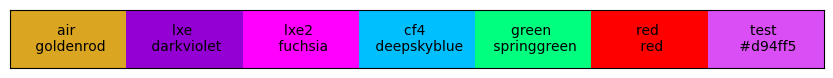

In [5]:
# show it off
ms.lxe.col
print(ms.names)

ms.show()

In [6]:
# # Define your custom style
# plt.rcParams['axes.titlesize'] = 20
# plt.rcParams['axes.labelsize'] = 14
# plt.rcParams['lines.linewidth'] = 2
# plt.rcParams['lines.markersize'] = 10
# plt.rcParams['xtick.labelsize'] = 12
# plt.rcParams['ytick.labelsize'] = 12

# Define your custom colors
plt.rcParams['axes.prop_cycle'] = plt.cycler(color=[ms.air.col, ms.lxe.col, ms.cf4.col, ms.green.col, ms.red.col, ms.test.col])

# plt.rcParams.keys()

# my_color = Style(color='r', linestyle='-')
# type(my_color)


In [7]:
## loading the data ##
rootPath1 = "../outputs_v1_noImaginary/"
rootPath2 = "../outputs_v2_allPhysics/"
rootPath3 = "../outputs_v3_amorphous/"
rootPath_validation = "../outputs_v4_finalTesting/"

savePath = "./dataOutputs/"

opticsPath_g4 = "../g4PDEsim/dataOptics/"
scintPath_g4 = "../g4PDEsim/data_cf4_scint/"

In [8]:
## Only load the air data
fnames = []
fnames.append("bulk amorphous") # A
fA = uproot.open(os.path.join(rootPath3, "bulk_air_N1e5_110-1050nm_0-85deg.root"))

fnames.append("passivation amorphous") # B
fB = uproot.open(os.path.join(rootPath3, "surface_air_N1e5_110-1050nm_0-85deg.root"))

fnames.append("bulk crystalline") # C
fC = uproot.open(os.path.join(rootPath2, "noQuartz_air_N1e5_120-1050nm_0-85deg.root"))

fnames.append("passivation crystalline") # D
fD = uproot.open(os.path.join(rootPath2, "noWindow_air_N1e5_120-1050nm_0-85deg.root"))
files = [fA, fB, fC, fD]

## getting trees
ttlist = [f["simOutput"] for f in files]

dflist = [ tt.arrays(library="pd").drop_duplicates() for tt in ttlist ]
for df, name in zip(dflist, fnames):
  df["eff"] = df["fNinBulk"]/df["fNphoton"]
  df["ref"] = 1-df["eff"]
  df.loc[:, "dfName"] = name

dfA = dflist[0]
dfB = dflist[1]
dfC = dflist[2]
dfD = dflist[3]

angles = dfA['fAngle'].unique()
print(angles)

column_names = ["fNphoton", "fPhotonWln", "fAngle", "fNonWindow", "fNonSurface", "fNonBulk", "fNinBulk"]

dfC.head(5)

[ 0.          5.00000214 10.00000429 14.99997778 20.00000857 24.99998207
 30.00001286 34.99998635 40.00001714 44.99999064 50.00002143 54.99999492
 60.00014031 64.99977003 69.9999727  75.00017538 79.9998051  85.00000778]


,fNphoton,fPhotonWln,fAngle,fNonWindow,fNonSurface,fNonBulk,fNinBulk,eff,ref,dfName
0,100000,120.023425,0.000000,0,0,45775,54225,0.54225,0.45775,bulk crystalline
1,100000,120.023425,19.400007,0,0,45861,54139,0.54139,0.45861,bulk crystalline
2,100000,120.023425,27.600007,0,0,46716,53284,0.53284,0.46716,bulk crystalline
3,100000,120.023425,34.000003,0,0,47377,52623,0.52623,0.47377,bulk crystalline
4,100000,120.023425,39.499997,0,0,48565,51435,0.51435,0.48565,bulk crystalline


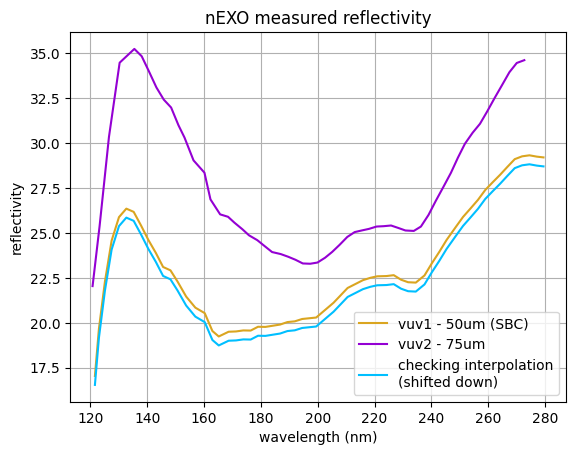

In [9]:
from scipy import interpolate

pdeX, pdeY = np.loadtxt(os.path.join(opticsPath_g4, "SiPMeff_Ham_5V.dat"), unpack=True, skiprows=1, delimiter = "\t")
pdeY *= 1./100

reg_dataPath = "../data_allOptics/"
rvuv = np.loadtxt(os.path.join(reg_dataPath, "vuv_Ref_air_nexo.csv"), skiprows=1, delimiter = ",")
column = rvuv[:, 1]

# Interpolate columns 1 and 2
f_interp1 = interpolate.interp1d(rvuv[:, 0], rvuv[:, 1])

# Interpolate columns 3 and 4
f_interp2 = interpolate.interp1d(rvuv[:, 2], rvuv[:, 3])

# Average the interpolated values
vuvR_x = rvuv[:, 0]
vuvR_x = np.sort(vuvR_x)
vuvR_y = f_interp1(vuvR_x) # only look at first SiPM



plt.plot(rvuv[:, 0], rvuv[:, 1], label = "vuv1 - 50um (SBC)")
plt.plot(rvuv[:, 2], rvuv[:, 3], label = "vuv2 - 75um")
plt.plot(vuvR_x, vuvR_y-0.5, label = "checking interpolation\n(shifted down)")
plt.legend()
plt.title("nEXO measured reflectivity")
plt.xlabel("wavelength (nm)")
plt.ylabel("reflectivity")
plt.grid()

vuvR_y = vuvR_y/100 if max(vuvR_y) > 1 else vuvR_y

[ 0.          5.00000214 10.00000429 14.99997778 20.00000857 24.99998207
 30.00001286 34.99998635 40.00001714 44.99999064 50.00002143 54.99999492
 60.00014031 64.99977003 69.9999727  75.00017538 79.9998051  85.00000778]


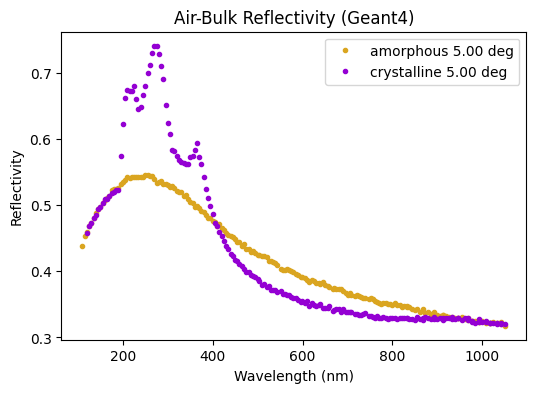

In [10]:
%matplotlib widget
%matplotlib inline

anglesC = dfC['fAngle'].unique()

dfA_specific = dfA[dfA["fAngle"] == angles[1]]
dfC_specific = dfC[dfC["fAngle"] == anglesC[1]]

thisName = dfA_specific["dfName"].values[0]
print(angles)

fig, (ax) = plt.subplots(1, 1, figsize=(6, 4))
dfA_specific.plot(x='fPhotonWln', y='ref', marker=".", linestyle="None", ax = ax, label=f"amorphous {angles[1]:0.2f} deg")
dfC_specific.plot(x='fPhotonWln', y='ref', marker=".", linestyle="None", ax = ax, label=f"crystalline {angles[1]:0.2f} deg")

plt.title("Air-Bulk Reflectivity (Geant4)")
plt.xlabel('Wavelength (nm)')
plt.ylabel('Reflectivity')
plt.show()
# plt.close('all')
print()


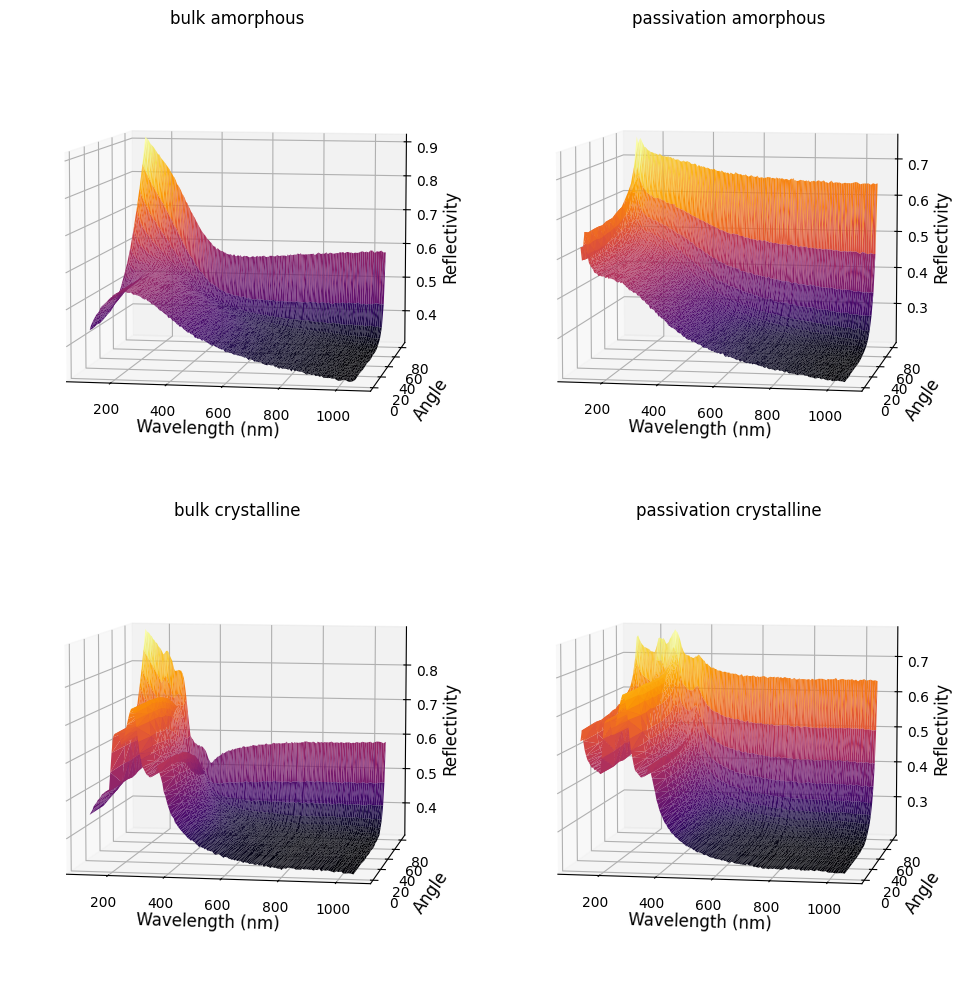

In [38]:
# %matplotlib widget
from mpl_toolkits.mplot3d import Axes3D
cmap = plt.colormaps.get_cmap('inferno')

fig = plt.figure(figsize=(10, 10))

# Plot for dfA
ax1 = fig.add_subplot(2, 2, 1, projection='3d')
ax1.plot_trisurf(dfA.fPhotonWln, dfA.fAngle, dfA.ref, cmap=cmap, linewidth=0.2)
ax1.set_title(dfA["dfName"].values[0])
ax1.set_xlabel('Wavelength (nm)', fontsize=12)
ax1.set_ylabel('Angle', fontsize=12)
ax1.set_zlabel('Reflectivity', fontsize=12)
ax1.view_init(elev=7, azim=-80)

# Plot for dfB
ax2 = fig.add_subplot(2, 2, 2, projection='3d')
ax2.plot_trisurf(dfB.fPhotonWln, dfB.fAngle, dfB.ref, cmap=cmap, linewidth=0.2)
ax2.set_title(dfB["dfName"].values[0])
ax2.set_xlabel('Wavelength (nm)', fontsize=12)
ax2.set_ylabel('Angle', fontsize=12)
ax2.set_zlabel('Reflectivity', fontsize=12)
ax2.view_init(elev=7, azim=-80)

# Plot for dfC
ax3 = fig.add_subplot(2, 2, 3, projection='3d')
ax3.plot_trisurf(dfC.fPhotonWln, dfC.fAngle, dfC.ref, cmap=cmap, linewidth=0.2)
ax3.set_title(dfC["dfName"].values[0])
ax3.set_xlabel('Wavelength (nm)', fontsize=12)
ax3.set_ylabel('Angle', fontsize=12)
ax3.set_zlabel('Reflectivity', fontsize=12)
ax3.view_init(elev=7, azim=-80)

# Plot for dfD
ax4 = fig.add_subplot(2, 2, 4, projection='3d')
ax4.plot_trisurf(dfD.fPhotonWln, dfD.fAngle, dfD.ref, cmap=cmap, linewidth=0.2)
ax4.set_title(dfD["dfName"].values[0])
ax4.set_xlabel('Wavelength (nm)', fontsize=12)
ax4.set_ylabel('Angle', fontsize=12)
ax4.set_zlabel('Reflectivity', fontsize=12)
ax4.view_init(elev=7, azim=-80)

plt.tight_layout()
plt.show()


In [12]:
# to find what you want
closestAngle = lambda df, angle: df["fAngle"].unique()[np.abs(df["fAngle"].unique() - angle).argmin()]
closestWlen = lambda df, wlen: df["fPhotonWln"].unique()[np.abs(df["fPhotonWln"].unique() - wlen).argmin()]

getDfforAngle = lambda df, angle: df[df["fAngle"] == closestAngle(df, angle)]
getDfforWlen = lambda df, wlen: df[df["fPhotonWln"] == closestWlen(df, wlen)]

removeDuplicates = lambda df, name = "fPhotonWln": df.loc[~df[name].duplicated(keep=False), :]

0       0.52642
1       0.52388
2       0.52661
3       0.52397
4       0.52724
         ...   
3397    0.25565
3398    0.29051
3399    0.34569
3400    0.44714
3401    0.63634
Name: ref, Length: 3402, dtype: float64
0.75593
0.26358886190536834


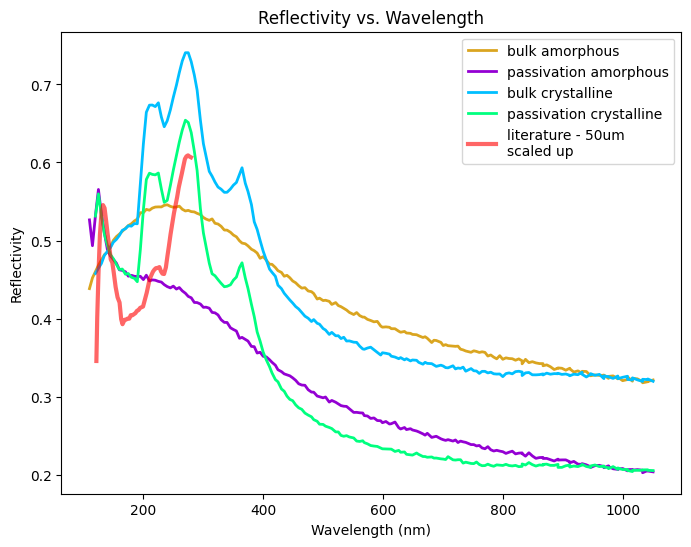

In [13]:
angleWanted = 0
# test = getDfforAngle(dfA, angleWanted)

# test.plot(x = "fPhotonWln", y = "ref", marker = ".", linestyle = "None")

fig, ax = plt.subplots(1, 1, figsize = (8, 6))

for df in dflist:
  df_plot = getDfforAngle(df, angleWanted)
  dfName = df_plot.dfName.unique()[0]
  
  ax.plot(df_plot.fPhotonWln, df_plot.ref, linewidth = 2, label = dfName)


dfScale = getDfforAngle(dfB, angleWanted)
dfScale = removeDuplicates(dfScale)

scaleLit = max(dfScale.ref)/max(vuvR_y[0:10])
print(dfB.ref)
print(max(dfB.ref))
print(max(vuvR_y[0:10]))
# scaleLit = 1


# ax.plot(rvuv[:, 0], rvuv[:, 1]/100, color = "r", linewidth = 2, label = "literature 1")
# ax.plot(rvuv[:, 2], rvuv[:, 3]/100, color = "r", linewidth = 2, label = "literature 1")
ax.plot(vuvR_x, vuvR_y*scaleLit - 0.02, color = "r", linewidth = 3, alpha = 0.6, label = "literature - 50um\nscaled up")

# ax.plot(pdeX, pdeY, color = "k", linewidth = 4, label = "Hamamatsu S13360-3050CS")

ax.set_xlabel("Wavelength (nm)")
ax.set_ylabel("Reflectivity")
ax.set_title("Reflectivity vs. Wavelength")
ax.legend()


In [14]:
# dfFinal = dfD.copy()
dfGood = dfD # passivation on crystalline surface
angleWanted = 0
dfFinal = getDfforAngle(dfGood, angleWanted)
removeDuplicates = lambda df: df.loc[~df['fPhotonWln'].duplicated(keep=False), :]
dfFinal = removeDuplicates(dfFinal)
# print(dfFinal)

r_f = interpolate.interp1d(dfFinal["fPhotonWln"], dfFinal["ref"], kind='cubic', fill_value="extrapolate")
# xvalues for r_f are dfFinal["fPhotonWln"]

pde_f = interpolate.interp1d(pdeX, pdeY, kind='cubic', fill_value="extrapolate")
# x values are pdeX

vuvR_f = interpolate.interp1d(rvuv[:, 0], rvuv[:, 1]/100, kind='cubic', fill_value="extrapolate")
# x values are vuvR_x

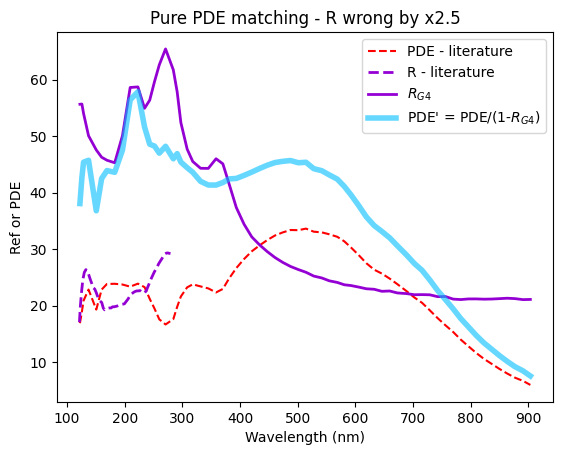

In [15]:
## Only getting PDE' correct (Ref will be wrong)

plt.plot(pdeX, 100* pdeY, color = "red", linestyle = "--", label = "PDE - literature")
plt.plot(vuvR_x, 100* vuvR_y, color = ms.lxe.col, linewidth = 2, linestyle = "--", label = "R - literature")

plt.plot(pdeX, 100 * r_f(pdeX), color = ms.lxe.col, linewidth = 2, linestyle = "-", label = r"$R_{G4}$")
plt.plot(pdeX, 100 * pdeY/(1 - r_f(pdeX)), color = ms.cf4.col, linewidth = 4, alpha = 0.6, label = r"PDE' = PDE/(1-$R_{G4}$)")


plt.title("Pure PDE matching - R wrong by x2.5")
plt.xlabel("Wavelength (nm)")
plt.ylabel("Ref or PDE")
plt.legend()

In [16]:
D = 0.17
# fixed numbers

# different x ranges
wlGap = 1
x_litR = np.arange(min(vuvR_x), max(vuvR_x), wlGap)
xplot_pde = np.arange(min(pdeX), max(pdeX), wlGap)

## rRatios
rRatio = vuvR_f(x_litR)/r_f(x_litR) # only known over literature range
# rRatio_f = lambda x: vuvR_f(x)/r_f(x)

Apartial = 1 - D - rRatio
A_flatEnd = np.append(Apartial, [Apartial[-1]]*(len(xplot_pde) - len(Apartial))) #extend last value
A_flat_fc = interpolate.interp1d(xplot_pde, A_flatEnd, kind='cubic', fill_value="extrapolate")

# now calculate PDE' with the 'normal' A values
# def calc_A_simple(wl, D):
#   return 1 - D - rRatio_f(wl)

def calc_pdeP(pde, A, R, D):
  return pde/(1 - A - D)/(1-R)

def calc_unityA(pde, R, D):
  return 1 - D - pde/(1-R)


pdeP_simplest_min = pde_f(xplot_pde) / (1 - r_f(xplot_pde)) / (1 - A_flat_fc(xplot_pde) - D)

A_massaged = []
pdeP_massaged = []
for wl in xplot_pde:
  
  A = A_flat_fc(wl) # calculated with VUV data extended with last value
  pdeTrue = pde_f(wl) # from manufacturer
  R_g4 = r_f(wl)      # from my study
  
  pdeP = calc_pdeP(pdeTrue, A, R_g4, D) # math with 'simple' A
  
  if pdeP > 1.0:
    A = calc_unityA(pdeTrue, R_g4, D)
    pdeP = calc_pdeP(pdeTrue, A, R_g4, D) # this should give 1.0
  
  A_massaged.append(A)
  pdeP_massaged.append(pdeP)
  
A_massaged = np.array(A_massaged)

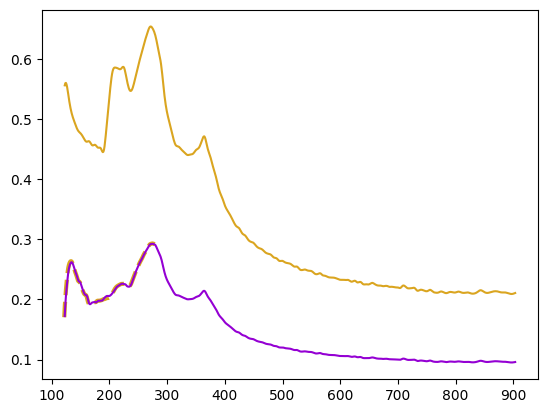

In [17]:
# why can't I make R values track one another?
# because A required to make R match makes PDE accurate impossible (PDE > 1)
plt.plot(x_litR, vuvR_f(x_litR), color = ms.air.col, linewidth = 3, linestyle = "--", label = "R - literature")

plt.plot(xplot_pde, r_f(xplot_pde), color = ms.air.col, label = "R - G4")

plt.plot(xplot_pde, r_f(xplot_pde) * (1 - A_flatEnd - D), color = ms.lxe.col, label = "R - G4")

"_summary_\n  R values can track one another. But in the 200 to 300 nm region,\n  too much is happening:\n  \n  the geant4 R is quite high, ~60%. to scale this down to the literature value of ~25,\n  and including the 17% diffuse reflectivity, we need to absorb around 40-50% of the photons\n  \n  Then when the (1-R)(1-A-D) photons make it through (to the active region), there aren't enough\n  to make the PDE' track the literature PDE and we get PDE' > 1.0 which we can't simulate\n  \n  SO. we do the calculation for A naively, which gives some PDE' > 1\n  then we change the A values to make PDE' = 1.0 (this corresponds to decreasing absorption)\n  This gets PDE' right, but increases the reflectivity a little bit. About 15% wrong in a small region\n  \n  \n  If we want, we can give A some other shape to increase R at longer wavelengths. PDE' should be self consistent.\n  But I think fixing it at the last value is okay. The Ref does still track the PDE quite well.\n"

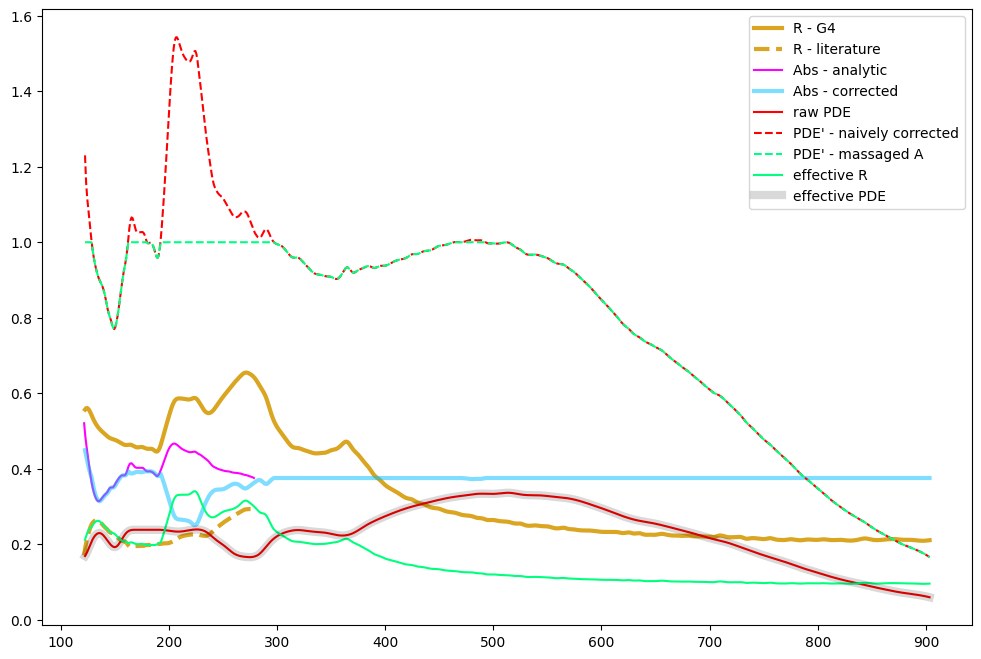

In [18]:


plt.figure(figsize = (12, 8))

plt.plot(xplot_pde, r_f(xplot_pde), color = ms.air.col, linewidth = 3, label = "R - G4")
plt.plot(x_litR, vuvR_f(x_litR), color = ms.air.col, linewidth = 3, linestyle = "--", label = "R - literature")

plt.plot(x_litR, Apartial, color = ms.lxe2.col, label = "Abs - analytic")
plt.plot(xplot_pde, A_massaged, color = ms.cf4.col, linewidth = 3, alpha = 0.5, label = "Abs - corrected")

# plt.plot(xplot_pde, A_massaged_Low, color = ms.cf4.col, linewidth = 4, linestyle = "--", alpha = 0.5, label = "Abs - corrected - LOW")

plt.plot(xplot_pde, pde_f(xplot_pde), color = ms.red.col, label = "raw PDE")
plt.plot(xplot_pde, pdeP_simplest_min, color = ms.red.col, linestyle = "--", label = "PDE' - naively corrected")
plt.plot(xplot_pde, pdeP_massaged, color = ms.green.col, linestyle = "--", label = "PDE' - massaged A")

plt.plot(xplot_pde, r_f(xplot_pde) * (1 - D - A_massaged), color = ms.green.col, label = "effective R")

# plt.plot(xplot_pde, r_f(xplot_pde) * (1 - D - A_massaged_Low), color = "darkGreen", linewidth = 3, label = "effective R - Low A")

plt.plot(xplot_pde, 0.0 + pdeP_massaged * (1 - A_massaged - D) * (1 - r_f(xplot_pde)), color = "k", alpha = 0.15, linewidth = 6, linestyle = "-", label = "effective PDE")

# plt.ylim(0, 0.45)

plt.legend()

"""_summary_
  R values can track one another. But in the 200 to 300 nm region,
  too much is happening:
  
  the geant4 R is quite high, ~60%. to scale this down to the literature value of ~25,
  and including the 17% diffuse reflectivity, we need to absorb around 40-50% of the photons
  
  Then when the (1-R)(1-A-D) photons make it through (to the active region), there aren't enough
  to make the PDE' track the literature PDE and we get PDE' > 1.0 which we can't simulate
  
  SO. we do the calculation for A naively, which gives some PDE' > 1
  then we change the A values to make PDE' = 1.0 (this corresponds to decreasing absorption)
  This gets PDE' right, but increases the reflectivity a little bit. About 15% wrong in a small region
  
  
  If we want, we can give A some other shape to increase R at longer wavelengths. PDE' should be self consistent.
  But I think fixing it at the last value is okay. The Ref does still track the PDE quite well.
"""

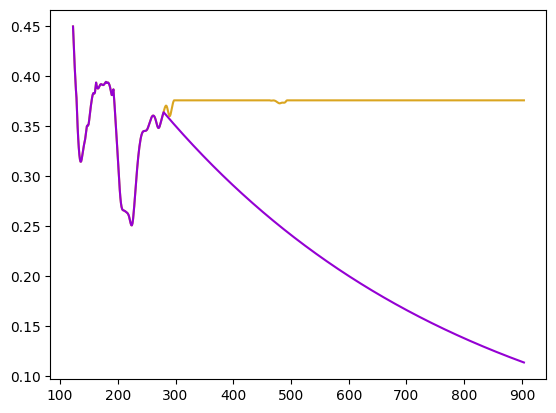

In [19]:
# changing the tail of A to see if things stay self consistent
A_massaged_Low = np.copy(A_massaged)
min_index = np.argmin(A_massaged_Low)
A_massaged_Low[min_index+1:] = np.min(A_massaged_Low)

A_low = np.copy(A_massaged)

# Find the index corresponding to the largest x value in x_litR
max_x_index = np.argmax(x_litR)

# Get the corresponding y value in A_massaged
start_y = A_massaged[max_x_index]

# Set the desired y value at x=600
end_y = 0.2

# Calculate the exponential decay factor
decay_factor = np.log(end_y / start_y) / (600 - x_litR[max_x_index])

# Update the values in A_low
for i in range(max_x_index, len(A_low)):
  x = xplot_pde[i]
  A_low[i] = start_y * np.exp(decay_factor * (x - x_litR[max_x_index]))

plt.plot(xplot_pde, A_massaged, label = "massaged")
plt.plot(xplot_pde, A_low, label = "low")

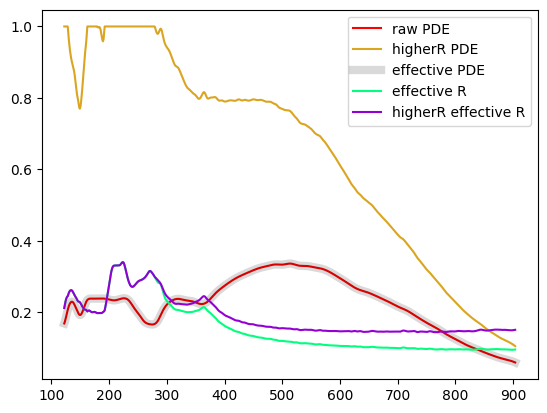

In [20]:
pdeP_low = pde_f(xplot_pde) / (1 - r_f(xplot_pde)) / (1 - A_low - D)
R_corrected = r_f(xplot_pde) * (1 - D - A_low)

plt.plot(xplot_pde, pde_f(xplot_pde), color = ms.red.col, label = "raw PDE")
plt.plot(xplot_pde, pdeP_low, label = "higherR PDE")
plt.plot(xplot_pde, 0.0 + pdeP_low * (1 - A_low - D) * (1 - r_f(xplot_pde)), color = "k", alpha = 0.15, linewidth = 6, linestyle = "-", label = "effective PDE")

plt.plot(xplot_pde, r_f(xplot_pde) * (1 - D - A_massaged), color = ms.green.col, label = "effective R")
plt.plot(xplot_pde, R_corrected, label = "higherR effective R")

plt.legend()

---
### Best Method - absorb photons on exit

In [21]:
# Yet another method. This time do the photon absorption after photons exit (see math and drawings)

# list of variables
## x lists
x_litR #literature range
xplot_pde # full

Rd = 0.17 # diffuse (flat)

## interpolation functions
pde_f # pde literature

r_f # geant4 reflectivity
f_interp1 # reflectivity data
vuvR_f # literature reflectivity but divided by 100

trans_short = vuvR_f(x_litR)/(1 - Rd)/r_f(x_litR)
trans_full = np.append(trans_short, np.repeat(trans_short[-1], len(xplot_pde)-len(trans_short)))

pdeP_better = pde_f(xplot_pde)/(1 - Rd)/(1 - r_f(xplot_pde))
xplot_pdeBetter = np.append(xplot_pde, 1100)
pdeP_better = np.append(pdeP_better, 0.0)

# np.savetxt(os.path.join(savePath,'effective_internalPDE.txt'), np.column_stack((xplot_pde, pdeP_better)), fmt='%f', delimiter='\t', header = "wavelength (nm), effective internal PDE from python calculation, giving correct overall PDE")
# np.savetxt(os.path.join(savePath,'effective_correction_transmission.txt'), np.column_stack((xplot_pde, trans_full)), fmt='%f', delimiter='\t', header = "wavelength (nm), transmission for correct effective R from python calculation")

print(pdeP_better[-3:])


[0.09195502 0.09088217 0.        ]


   fNphoton  fPhotonWln     fAngle  fNonWindow  fNonSurface  fNonBulk   
0    500000  110.012598   0.000000           0       221026    193820  \
1    500000  110.012598  39.499997           0       215929    199261   
2    500000  110.012598  57.100000           0       215351    199727   
3    500000  110.012598  71.600244           0       238728    176733   
4    500000  110.012598  85.000008           0       331096     84146   

   fNinBulk  fNinBulkPDE  
0    197059        90333  
1    189972        86950  
2    176616        80718  
3    158977        73125  
4    101948        46836  
---------------
angles: [ 0.         39.49999688 57.09999983 71.60024383 85.00000778] 
---------------


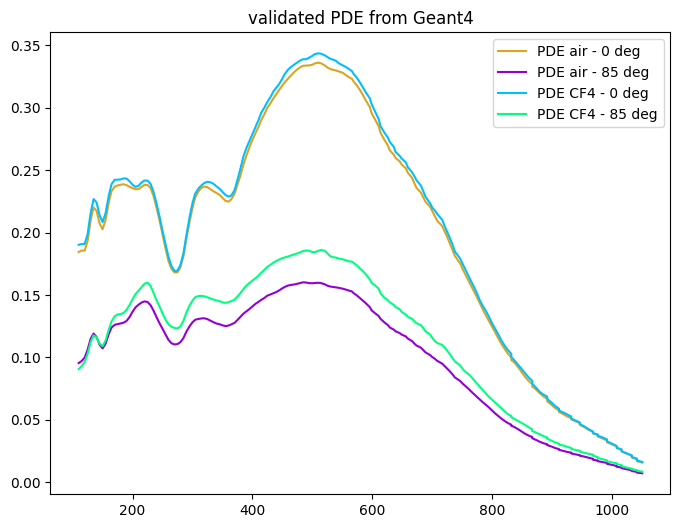

In [53]:
from scipy.ndimage import gaussian_filter1d
f_validation = uproot.open(os.path.join(rootPath_validation, "final_air_N5e5_110-1050nm_0-85deg.root"))

ttValid = f_validation["simOutput"]
dfValid_full = ttValid.arrays(library="pd").drop_duplicates()
print(dfValid_full.head(5))
dfValid_full["pde_eff"] = dfValid_full["fNinBulkPDE"]/dfValid_full["fNphoton"]
print("---------------\nangles:", dfValid_full['fAngle'].unique(), "\n---------------")

angle1 = 0
dfValid = getDfforAngle(dfValid_full, angle1)
removeDuplicates(dfValid)

angle2 = 85
dfValid2 = getDfforAngle(dfValid_full, angle2)
removeDuplicates(dfValid2)

smoothSig = 1.
fig, ax = plt.subplots(figsize = (8, 6))
ax.set_title("validated PDE from Geant4")

ax.plot(dfValid["fPhotonWln"], gaussian_filter1d(dfValid["pde_eff"], sigma=smoothSig), label = f"PDE air - {angle1:0.0f} deg")
ax.plot(dfValid2["fPhotonWln"], gaussian_filter1d(dfValid2["pde_eff"], sigma=smoothSig), label = f"PDE air - {angle2:0.0f} deg")

## for CF4
f_validation_cf4 = uproot.open(os.path.join(rootPath_validation, "final_lcf4_N1e5_110-1050nm_0-85deg.root"))
tt_valid_cf4 = f_validation_cf4["simOutput"]
df_valid_cf4_full = tt_valid_cf4.arrays(library="pd").drop_duplicates()
# print(df_valid_cf4_full.head(5))
df_valid_cf4_full["pde_eff"] = df_valid_cf4_full["fNinBulkPDE"]/df_valid_cf4_full["fNphoton"]

dfValid_cf4 = getDfforAngle(df_valid_cf4_full, angle1)
removeDuplicates(dfValid_cf4)

dfValid2_cf4 = getDfforAngle(df_valid_cf4_full, angle2)
removeDuplicates(dfValid2_cf4)

ax.plot(dfValid_cf4["fPhotonWln"], gaussian_filter1d(dfValid_cf4["pde_eff"], sigma=smoothSig), label = f"PDE CF4 - {angle1:0.0f} deg")
ax.plot(dfValid2_cf4["fPhotonWln"], gaussian_filter1d(dfValid2_cf4["pde_eff"], sigma=smoothSig), label = f"PDE CF4 - {angle2:0.0f} deg")

ax.legend()
plt.show()

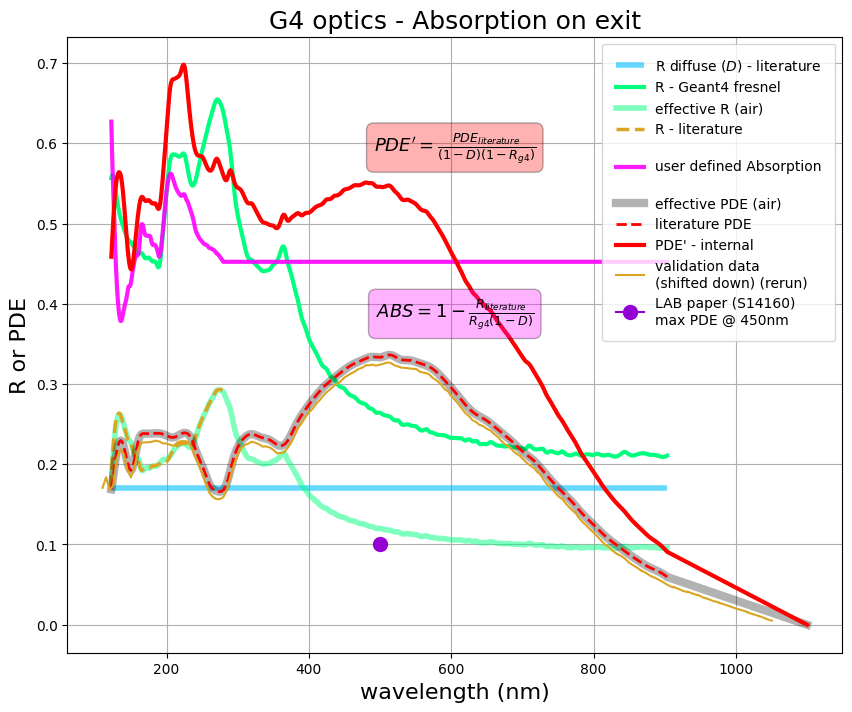

In [54]:
import matplotlib.patheffects as path_effects
plt.figure(figsize = (10, 8))

plt.hlines(Rd, min(xplot_pde), max(xplot_pde), linewidth = 4, linestyle = "-", alpha = 0.6, color = ms.cf4.col, label = r"R diffuse ($D$) - literature")
plt.plot(xplot_pde, r_f(xplot_pde), color = ms.green.col, linewidth = 3, label = "R - Geant4 fresnel")
plt.plot(xplot_pde, r_f(xplot_pde) * (1-Rd) * (trans_full), color = ms.green.col, alpha = 0.5, linewidth = 4, linestyle = "-", label = "effective R (air)")
plt.plot(x_litR, vuvR_f(x_litR), color = ms.air.col, linewidth = 2.5, linestyle = "--", label = "R - literature")

plt.plot(xplot_pde, 1 - trans_full, color = ms.lxe2.col, alpha = 0.9, linewidth = 3, label = "\nuser defined Absorption\n")

plt.plot(xplot_pdeBetter, pdeP_better * (1-Rd) * (1 - r_f(xplot_pdeBetter)), color = 'k', linewidth = 6, alpha = 0.3, label = "effective PDE (air)")
plt.plot(xplot_pde, pde_f(xplot_pde), linestyle = "--", linewidth = 2, color = ms.red.col, label = "literature PDE")
plt.plot(xplot_pdeBetter, pdeP_better, color = ms.red.col, linewidth = 3, label = "PDE' - internal")

## validation data
plt.plot(dfValid["fPhotonWln"].values, dfValid["pde_eff"].values - 0.01, color = ms.air.col, label = "validation data \n(shifted down) (rerun)")

bboxComs =dict(facecolor=ms.lxe2.col, alpha = 0.3, edgecolor='black', boxstyle='round,pad=0.4')
tmath = plt.text(0.5, 0.55, r"$ABS = 1-\frac{R_{literature}}{R_{g4}(1 - D)}$", fontsize = 13, transform=plt.gca().transAxes, ha='center', va='center', bbox = bboxComs)

bboxComs2 =bboxComs.copy()
bboxComs2["facecolor"] = ms.red.col
tmath = plt.text(0.5, 0.82, r"$PDE' = \frac{PDE_{literature}}{(1 - D)(1-R_{g4})}$", fontsize = 13, transform=plt.gca().transAxes, ha='center', va='center', bbox = bboxComs2) 
# tmath.set_path_effects([path_effects.withStroke(linewidth=2, foreground='black'), path_effects.Normal()])

# some data from LAB reflectivity paper
plt.plot(500, 0.1, marker = "o", markersize = 10, color = ms.lxe.col, label = "LAB paper (S14160)\nmax PDE @ 450nm")

plt.title("G4 optics - Absorption on exit", fontsize = 18)
plt.xlabel("wavelength (nm)", fontsize = 16)
plt.ylabel("R or PDE", fontsize = 16)
plt.legend(fancybox = 1, borderpad=1)

# plt.ylim(0, 0.40)
# plt.xlim(150, 550)
plt.grid()
# plt
plt.show()

---
### Checking angular dependance at high angles

data from other simulations gives too many photons detected.
Could it be possible that PDE is too high at large incidence angles?

In [ ]:
xSave = xplot_pde
ySave = r_f(xplot_pde) * (1-Rd) * (trans_full)
np.savetxt(os.path.join(savePath,'effective_Ref_air-forDavid.txt'), np.column_stack((xSave, ySave)), fmt='%f', delimiter='\t', header = "wavelength (nm), Reflectivity for correct effective R from G4 study")